# 03 - Error propagation: what happens when the wind is uncertain?

One of our goals with this project is to give an intuition for how to think about the way input errors translate into output errors. As we see in out example, we can never know the wind exactly. The power prediction is $\hat P = P(\hat v)$, where $\hat v$ is the input wind speed with some
prediction error and $P(\cdot)$ is our power curve from notebook 02. In this notebook we look at how an error in the wind shows up in the power.
A naive intuition could be "10 % wrong wind gives 10 % wrong power" which is why we start by testing this intuition on some examples of various input noise values and observe the output noise. 

We use simulated noise instead of real weather forecasts becasue in our tries with historical wind forecasts from the Open-Meteo API we realized that the input error mixes a lot of different effects which obscures the main point. There are multiple factors that obscure the relation between prediction error and power output error. Such effects are deviation in windspeed prediction height (80 m) compared to exact hub height (69m), the measurement error of the
anemometer on the nacelle, the grid cell resolution of the forecast (9km), and a bias of 0.6-0.8 m/s, which all add up to one relatively large, unevenly distributed input error. This obscures the prediction error propagation through our model which is why we chose to control the input uncertainty ourselves: we take the measured wind of the calibration hours and for three seperate cases add Gaussian noise of 1 %, 5 % and 10 %. This is later compared to the real forecasts in notebook 05.

Steps:
1. Load the curve and the calibration hours
2. Add noise to the wind values
3. What the noise does to the power
4. How big are the errors? Wind vs. power
5. Gaussian error propagation
6. Where does the factor 3 hold?
7. Are the power errors normally distributed?
8. Same check in the bend: why a ± σ band is not an interval
9. Save for notebook 04

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from scipy.interpolate import PchipInterpolator
from scipy.stats import norm

NOISE_LEVELS = [0.01, 0.05, 0.10]                         # relative wind noise: v_noise = v * (1 + level * eps), eps ~ N(0, 1)
NOISE_COLUMNS = ["v_noise_1", "v_noise_5", "v_noise_10"]  # column with the noisy wind for each noise level
NOISE_SEED = 1               # fixed seed so that we all get the same noise
MC_DRAWS = 200_000           # draws of the wind noise for one hour (Monte Carlo check at one wind speed)
MC_SEED = 0                  # own seed for these draws, so the noise of the calibration hours stays the same
STEEP_PART = (4.0, 10.0)     # m/s, middle part of the curve where the cubic law roughly holds
WIND_BINS = [0, 3, 5, 7, 9, 11, np.inf]   # m/s, bins of the predicted wind (same bins as for Mondrian in notebook 04)
WIND_BIN_LABELS = ["0–3 m/s", "3–5 m/s", "5–7 m/s", "7–9 m/s", "9–11 m/s", "≥ 11 m/s"]
Z_90 = norm.ppf(0.95)        # 1.645: mean +/- 1.645 sigma contains 90 % of a normal distribution

# colors of the slide deck (taken from the title photo of the presentation)
DEEP = "#3d5687"        # deep sky: bin means, emphasis
BLUE = "#5b86bd"        # sky: wind
LIGHT_BLUE = "#9dbbe0"  # light sky: data points behind a curve
TEAL = "#6fa9b6"        # horizon teal: second series
ORANGE = "#e8673a"      # blade tip: power
GRAY = "#b9c3cd"        # light haze: context
DARK_GRAY = "#6e7f8f"   # dark haze: axes and context points
INK = "#24324a"         # text and lines

# the plots that are on the slides are saved here, at the size they have on the slide
FIGURE_DIR = "Presentation/figures"

# font of the slides: Aptos comes with PowerPoint, without PowerPoint we use Arial
APTOS_DIR = Path("/Applications/Microsoft PowerPoint.app/Contents/Resources/DFonts")
for font_file in APTOS_DIR.glob("Aptos*.ttf"):
    font_manager.fontManager.addfont(str(font_file))
if (APTOS_DIR / "Aptos.ttf").exists():
    FONT = "Aptos"
else:
    FONT = "Arial"

plt.rcParams.update({
    "font.family": FONT,
    "font.size": 10,
    "axes.labelsize": 10.5,
    "axes.labelcolor": INK,
    "axes.edgecolor": DARK_GRAY,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6eaee",
    "grid.linewidth": 0.6,
    "xtick.color": DARK_GRAY,
    "ytick.color": DARK_GRAY,
    "xtick.labelcolor": INK,
    "ytick.labelcolor": INK,
    "legend.frameon": False,
    "figure.dpi": 150,    # shows the small slide figures a bit larger in the notebook
    "savefig.dpi": 220,   # resolution of the saved slide figures
    "mathtext.fontset": "custom",
    "mathtext.rm": FONT,
    "mathtext.it": FONT + ":italic",
    "mathtext.cal": FONT,   # we use no cursive math; the default cursive font of the Mac gives a font warning
})

def style_power_axes(ax, xlabel="wind speed v [m/s]"):
    """Axes of the wind speed vs. power plots, the same on every slide.

    Args:
        ax: Matplotlib axes.
        xlabel: Label of the x axis.
    """
    ax.set_xlim(0, 17)
    ax.set_xticks([0, 5, 10, 15])
    ax.set_ylim(-60, 1150)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("power P [kW]")
    ax.grid(axis="x", visible=False)

## 1. Curve and calibration hours

Both come from notebook 02:
- the power curve fitted on the training hours. We rebuild it from the saved bin table, together with its slope $P'(v)$, which we need
  for the error propagation,
- the calibration hours: 20 % of the cleaned hours that were not used to fit the curve. We use them here and for the conformal
  intervals in notebook 04.

In [2]:
def power_curve(table, v):
    """Power from the PCHIP curve through the bin means (same as in notebook 02).

    Below the first bin the power is 0, above the last bin it stays at the power of the last bin.

    Args:
        table: Bin table with the bin means in the columns ``v`` (m/s) and ``p`` (kW).
        v: Wind speeds in m/s.

    Returns:
        Array with the power in kW for each wind speed.
    """
    v = np.asarray(v, dtype=float)
    v_first = table["v"].iloc[0]
    v_last = table["v"].iloc[-1]
    pchip = PchipInterpolator(table["v"], table["p"])
    p = pchip(np.clip(v, v_first, v_last))
    p = np.where(v < v_first, 0.0, p)
    p = np.where(v > v_last, table["p"].iloc[-1], p)
    return p


def power_curve_slope(table, v):
    """Slope P'(v) of the PCHIP curve through the bin means (0 outside the bins).

    Args:
        table: Bin table with the bin means in the columns ``v`` (m/s) and ``p`` (kW).
        v: Wind speeds in m/s.

    Returns:
        Array with the slope in kW per m/s for each wind speed.
    """
    v = np.asarray(v, dtype=float)
    v_first = table["v"].iloc[0]
    v_last = table["v"].iloc[-1]
    slope = PchipInterpolator(table["v"], table["p"]).derivative()
    dp = slope(np.clip(v, v_first, v_last))
    dp = np.where((v < v_first) | (v > v_last), 0.0, dp)
    return dp


# bin table of the power curve from notebook 02
bins = pd.read_csv("data/power_curve_bins.csv")

# calibration hours from notebook 02 (cleaned, not used to fit the curve)
hours = pd.read_csv("data/scada_hours.csv", parse_dates=["time_local"])
cal = hours.loc[hours["split"] == "calibration", ["time_local", "v", "p"]].reset_index(drop=True)
mean_v = cal["v"].mean()
mean_p = cal["p"].mean()
print(f"{len(cal)} calibration hours, mean wind {mean_v:.2f} m/s, mean power {mean_p:.1f} kW")

1594 calibration hours, mean wind 5.26 m/s, mean power 247.4 kW


## 2. Add noise to the wind

We simulate an uncertain wind prediction:

$$\hat v = v \cdot (1 + s\,\varepsilon), \qquad \varepsilon \sim N(0, 1), \qquad s = 1\,\%,\ 5\,\%,\ 10\,\%$$

- The noise is relative: $s$ is the standard deviation relative to the wind of that hour, $\sigma_v / v = s$. So 10 % noise is 0.3 m/s
  at 3 m/s and 1.2 m/s at 12 m/s. This is the same $\sigma_v / v$ as in the error propagation formula in section 5.
- We draw one $\varepsilon$ per hour and scale it to each level. Then the three noisy versions only differ in the size of the noise and
  not by chance.
- The noise has mean 0, so there is no bias. Negative wind speeds are practically impossible at these levels ($\varepsilon < -10$
  would be needed), but we set them to 0 anyway.

In [3]:
# one standard normal draw per hour, scaled to each noise level
rng = np.random.default_rng(NOISE_SEED)
eps = rng.standard_normal(len(cal))
for level, column in zip(NOISE_LEVELS, NOISE_COLUMNS):
    cal[column] = np.clip(cal["v"] * (1 + level * eps), 0, None)
cal.head()

,time_local,v,p,v_noise_1,v_noise_5,v_noise_10
0,2025-01-01 08:00:00,3.9,42.8,3.913478,3.967389,4.034778
1,2025-01-01 16:00:00,4.3,76.6,4.335330,4.476648,4.653296
2,2025-01-01 21:00:00,5.2,172.4,5.217183,5.285914,5.371827
3,2025-01-02 00:00:00,5.4,182.7,5.329630,5.048148,4.696295
4,2025-01-02 07:00:00,5.6,195.4,5.650700,5.853500,6.106999


## 3. What the noise does to the power

For each noise level there are two plots, as on the slide.
**Input (first plot):** the noisy wind $\hat v$ against the measured wind $v$.
**Output (second plot):** the power predicted from the noisy wind, $P(\hat v)$, against the measured wind. The dark line is the prediction
with the exact wind, so the vertical spread is the power error caused only by the wind noise (the model error is treated by the conformal prediction in
notebook 04).

The cone of wind errors turns into a "tube" around the power curve. It is wide on the steep part and closes where the curve is flat
(below cut-in and at rated power). With 1 % noise the tube is too thin to see.

wind ± 1%


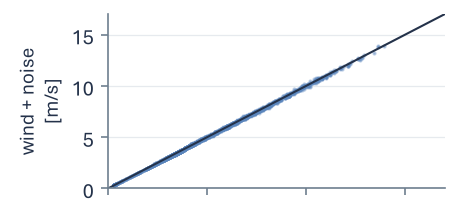

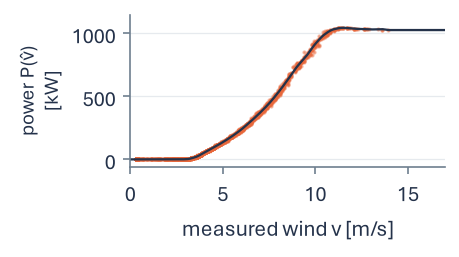

wind ± 5%


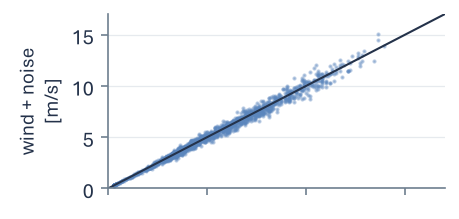

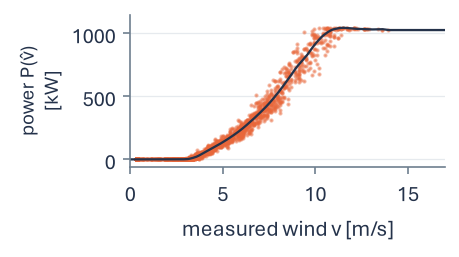

wind ± 10%


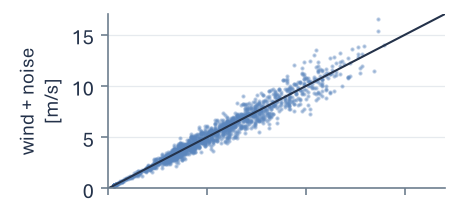

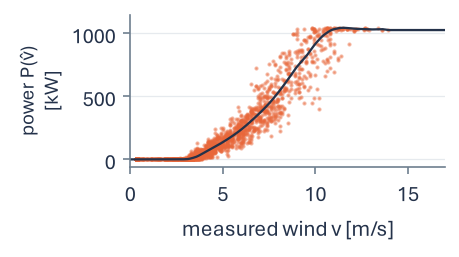

In [4]:
# input (noisy vs. measured wind) and output (predicted power vs. measured wind) for each noise level,
# at the size they have on the slide (slide 12, one column per noise level)
v_grid = np.linspace(0, 17, 1000)
for i in range(len(NOISE_LEVELS)):
    level = NOISE_LEVELS[i]
    column = NOISE_COLUMNS[i]
    number = column.replace("v_noise_", "")   # "1", "5" or "10", for the file names
    print(f"wind ± {level:.0%}")

    # input: a cone around the line of no noise
    fig, ax = plt.subplots(figsize=(2.95, 1.35), layout="constrained")
    ax.plot(cal["v"], cal[column], ".", ms=2, color=BLUE, alpha=0.4, rasterized=True)
    ax.plot([0, 17], [0, 17], color=INK, lw=1)
    ax.set(xlim=(0, 17), ylim=(0, 17), xticks=[0, 5, 10, 15], yticks=[0, 5, 10, 15], xticklabels=[])
    ax.set_ylabel("wind + noise\n[m/s]", fontsize=9.5)
    ax.grid(axis="x", visible=False)
    fig.savefig(f"{FIGURE_DIR}/noise_input_{number}.png", transparent=False, facecolor="white")
    plt.show()

    # output: a tube around the curve with the exact wind
    fig, ax = plt.subplots(figsize=(2.95, 1.6), layout="constrained")
    ax.plot(cal["v"], power_curve(bins, cal[column]), ".", ms=2, color=ORANGE, alpha=0.45, rasterized=True)
    ax.plot(v_grid, power_curve(bins, v_grid), color=INK, lw=1.1)
    style_power_axes(ax, xlabel="measured wind v [m/s]")
    ax.set_yticks([0, 500, 1000])
    ax.set_ylabel("power P(v̂)\n[kW]", fontsize=9.5)
    fig.savefig(f"{FIGURE_DIR}/noise_output_{number}.png", transparent=False, facecolor="white")
    plt.show()

## 4. How big are the errors? Wind vs. power

For each noise level we compare the wind error $\Delta v = \hat v - v$ with the power error it causes, $\Delta P = P(\hat v) - P(v)$.
- **MAE** (mean absolute error) is the typical size of an error. **RMSE** (root mean squared error) gives more weight to large errors,
  and it is also what Gaussian error propagation predicts (its $\sigma$ is an RMSE). So we expect the factor 3 to show up in the RMSE.
- **Bias** (mean error) is just a check here: noise with mean 0 should give (almost) no bias.
- The direct test of $\sigma_P / P = 3\,\sigma_v / v$ is done hour by hour on the steep part (4-10 m/s): the relative power error of each
  hour ($\Delta P / P$) against its relative wind error ($\Delta v / v$). Below cut-in $P$ is about 0, so a relative error makes no sense there.
- Over all hours we divide the errors by the mean wind and the mean power. Because the noise is relative to the wind of each hour, the
  wind RMSE in % of the mean wind is a bit higher than the noise level (1.2 % for 1 %).

In [5]:
def rmse(err):
    """Root mean squared error.

    Args:
        err: Errors.

    Returns:
        The RMSE, in the unit of ``err``.
    """
    return float(np.sqrt(np.mean(np.square(err))))


# power with the exact wind, and which hours are on the steep part
p_exact = power_curve(bins, cal["v"])
steep = cal["v"].between(STEEP_PART[0], STEEP_PART[1])

# wind and power errors for each noise level (relative to the mean wind and the mean power)
rows = {}
for level, column in zip(NOISE_LEVELS, NOISE_COLUMNS):
    dv = cal[column] - cal["v"]
    dp = power_curve(bins, cal[column]) - p_exact
    wind_rmse = rmse(dv) / mean_v
    power_rmse = rmse(dp) / mean_p
    wind_mae = dv.abs().mean() / mean_v
    power_mae = np.abs(dp).mean() / mean_p
    # steep part: relative power error of each hour vs. its relative wind error
    ratio_steep = rmse(dp[steep] / p_exact[steep]) / rmse(dv[steep] / cal["v"][steep])
    rows[f"wind ± {level:.0%}"] = {
        "power RMSE [kW]": rmse(dp),
        "ratio RMSE, steep part": ratio_steep,
        "wind RMSE": wind_rmse,
        "power RMSE": power_rmse,
        "ratio RMSE": power_rmse / wind_rmse,
        "wind MAE": wind_mae,
        "power MAE": power_mae,
        "ratio MAE": power_mae / wind_mae,
        "wind bias": dv.mean() / mean_v,
        "power bias": dp.mean() / mean_p,
    }
errors = pd.DataFrame(rows).T

print(f"steep part: {steep.mean():.0%} of the calibration hours")
errors.style.format({"power RMSE [kW]": "{:.0f}", "ratio RMSE, steep part": "{:.1f}x",
                     "wind RMSE": "{:.1%}", "power RMSE": "{:.1%}", "ratio RMSE": "{:.1f}x",
                     "wind MAE": "{:.1%}", "power MAE": "{:.1%}", "ratio MAE": "{:.1f}x",
                     "wind bias": "{:.1%}", "power bias": "{:.1%}"})

steep part: 55% of the calibration hours


,power RMSE [kW],"ratio RMSE, steep part",wind RMSE,power RMSE,ratio RMSE,wind MAE,power MAE,ratio MAE,wind bias,power bias
wind ± 1%,8,3.3x,1.2%,3.3%,2.9x,0.8%,1.9%,2.4x,-0.0%,-0.1%
wind ± 5%,41,3.3x,5.8%,16.5%,2.8x,4.1%,9.5%,2.3x,-0.2%,-0.7%
wind ± 10%,80,3.3x,11.6%,32.5%,2.8x,8.1%,18.8%,2.3x,-0.4%,-1.3%


## 5. Gaussian error propagation

For errors in the middle part of the curve, the curve is aproximately a straight line, so $\Delta P \approx P'(v)\,\Delta v$. This means the spread of the power
error is the spread of the wind error times the slope (Gaussian or linear error propagation):

$$\sigma_P = \sqrt{\left(P'(v)\,\sigma_v\right)^2} = |P'(v)|\,\sigma_v$$

For the cubic law $P = c\,v^3$ the slope is $P' = 3c\,v^2$, and if we divide by $P$ we get

$$\frac{\sigma_P}{P} = 3\,\frac{\sigma_v}{v}$$

so the relative power error in that part of the curve is three times the relative wind error. With our curve and our noise ($\sigma_v = s\,v$) we can predict the
power error of every hour as $|P'(v)|\,s\,v$ and compare its RMSE over all hours with the observed RMSE from section 4.

The plot shows the example at 7 m/s: the narrow blue band is the wind error, the much wider orange band the power error it causes.

,observed power RMSE,Gaussian prediction,difference [pp]
wind ± 1%,3.3%,3.2%,-0.1
wind ± 5%,16.5%,16.1%,-0.3
wind ± 10%,32.5%,32.3%,-0.2


at 7 m/s: P = 369 kW, P' = 143 kW per m/s; +/-10% wind (+/-0.7 m/s) -> +/-100 kW = +/-27% power


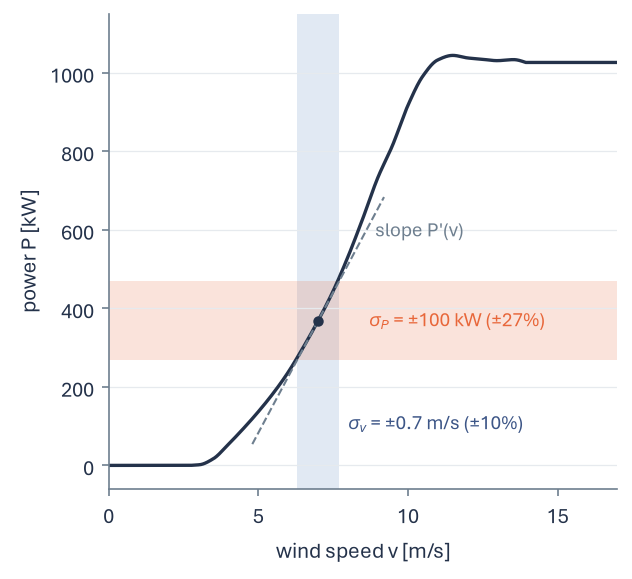

In [6]:
# power RMSE predicted by the error propagation vs. the observed power RMSE
rows = {}
for level in NOISE_LEVELS:
    label = f"wind ± {level:.0%}"
    predicted = rmse(np.abs(power_curve_slope(bins, cal["v"])) * level * cal["v"]) / mean_p
    rows[label] = {"observed power RMSE": errors.loc[label, "power RMSE"], "Gaussian prediction": predicted}
gauss = pd.DataFrame(rows).T
gauss["difference [pp]"] = 100 * (gauss["Gaussian prediction"] - gauss["observed power RMSE"])
display(gauss.style.format({"observed power RMSE": "{:.1%}", "Gaussian prediction": "{:.1%}", "difference [pp]": "{:+.1f}"}))

# example: one hour at 7 m/s with 10 % wind noise
v_0 = 7.0
s_0 = 0.10
p_0 = float(power_curve(bins, v_0))
slope_0 = float(power_curve_slope(bins, v_0))
sigma_p = slope_0 * s_0 * v_0
print(f"at {v_0:.0f} m/s: P = {p_0:.0f} kW, P' = {slope_0:.0f} kW per m/s; "
      f"+/-{s_0:.0%} wind (+/-{s_0 * v_0:.1f} m/s) -> +/-{sigma_p:.0f} kW = +/-{sigma_p / p_0:.0%} power")

# the example as a plot: the narrow wind band (blue) turns into a much wider power band (orange) through the slope (slide 13)
sigma_v = s_0 * v_0
fig, ax = plt.subplots(figsize=(4.1, 3.75), layout="constrained")
ax.axvspan(v_0 - sigma_v, v_0 + sigma_v, color=BLUE, alpha=0.18, lw=0)
ax.axhspan(p_0 - sigma_p, p_0 + sigma_p, color=ORANGE, alpha=0.18, lw=0)
ax.plot(v_grid, power_curve(bins, v_grid), color=INK, lw=1.6)
# tangent at the example point, its slope is P'(v)
ax.plot([v_0 - 2.2, v_0 + 2.2], [p_0 - 2.2 * slope_0, p_0 + 2.2 * slope_0], "--", color=DARK_GRAY, lw=1)
ax.plot([v_0], [p_0], "o", color=INK, ms=4)
ax.annotate(f"$\\sigma_v$ = ±{sigma_v:.1f} m/s (±{s_0:.0%})", (v_0 + sigma_v + 0.3, 90), color=DEEP, fontsize=9.5)
ax.annotate(f"$\\sigma_P$ = ±{sigma_p:.0f} kW (±{sigma_p / p_0:.0%})", (8.7, p_0), va="center", color=ORANGE, fontsize=9.5)
ax.annotate("slope P′(v)", (v_0 + 1.9, p_0 + 1.5 * slope_0), color=DARK_GRAY, fontsize=9.5, ha="left")
style_power_axes(ax)
fig.savefig(f"{FIGURE_DIR}/gauss_illustration.png", transparent=False, facecolor="white")
plt.show()

Gaussian error propagation only gives the size of the power error, $\sigma_P$. To see the whole distribution we simulate the hour at
7 m/s many times (Monte Carlo): $\hat v = 7 \cdot (1 + 0.10\,\varepsilon)$ with 200 000 draws of $\varepsilon$, and the power $P(\hat v)$
for each draw. In the plot the blue bell is the distribution of the wind and the orange histogram the distribution of the power. The
dashed line is the normal distribution that Gaussian error propagation assumes, with $\sigma_P$ from above. We leave out the
tangent here: the slope is not the same over the whole wind band, so one fixed slope would be confusing.

We use draws instead of the formula so that we can do exactly the same check in the bend in section 8. The draws have their own seed,
so the noise of the calibration hours does not change. At 7 m/s the power is close to a normal distribution, only a bit lopsided
(the upper tail is longer).

at 7 m/s, 200,000 draws: power error -148 / +192 kW (5 % / 95 %), Gaussian -165 / +165 kW


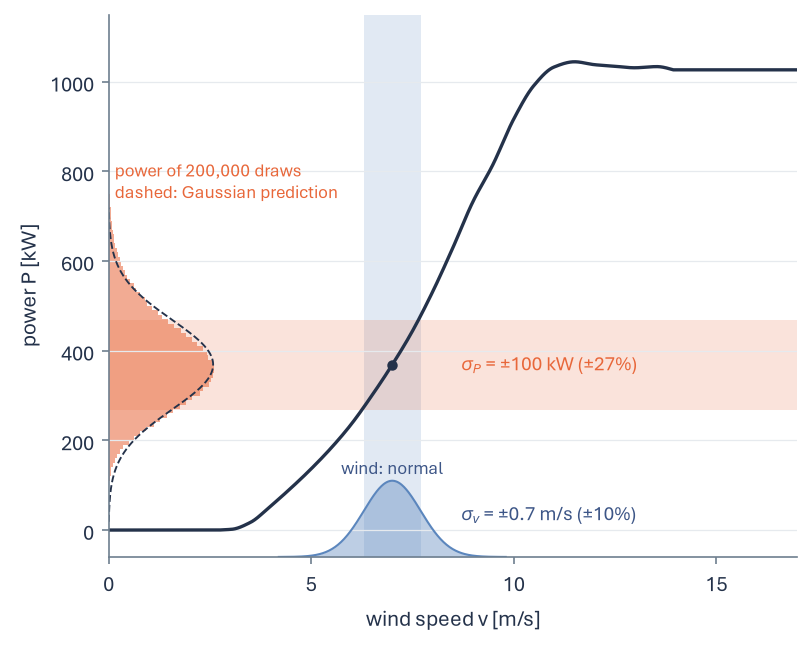

In [7]:
def power_error_draws(v, level, eps):
    """Power errors of one hour for many draws of the wind noise (Monte Carlo).

    Args:
        v: True wind speed in m/s.
        level: Relative wind noise, for example 0.10 for 10 %.
        eps: Standard normal draws, one per simulated wind.

    Returns:
        Array with the power error P(v_noise) - P(v) in kW for each draw.
    """
    v_noise = np.clip(v * (1 + level * eps), 0, None)
    return power_curve(bins, v_noise) - float(power_curve(bins, v))


def draw_gauss_panel(ax, v, level):
    """Power curve with the wind band and the power band of Gaussian error propagation at one wind speed.

    Blue: the wind band v +/- sigma_v and the normal distribution of the wind as a bell on the x axis.
    Orange: the power band P(v) +/- |P'(v)| sigma_v.

    Args:
        ax: Matplotlib axes.
        v: Wind speed in m/s.
        level: Relative wind noise, sigma_v = level * v.

    Returns:
        Tuple ``(p, sigma_v, sigma_p)``: power at v in kW, sigma of the wind in m/s and sigma of the power in kW.
    """
    p = float(power_curve(bins, v))
    slope = float(power_curve_slope(bins, v))
    sigma_v = level * v
    sigma_p = abs(slope) * sigma_v
    ax.axvspan(v - sigma_v, v + sigma_v, color=BLUE, alpha=0.18, lw=0)
    ax.axhspan(p - sigma_p, p + sigma_p, color=ORANGE, alpha=0.18, lw=0)
    # normal distribution of the wind as a bell on the x axis (170 kW high at its top)
    v_bell = np.linspace(v - 4 * sigma_v, v + 4 * sigma_v, 300)
    bell = 170 * norm.pdf(v_bell, v, sigma_v) / norm.pdf(v, v, sigma_v)
    ax.fill_between(v_bell, -60, -60 + bell, color=BLUE, alpha=0.4, lw=0)
    ax.plot(v_bell, -60 + bell, color=BLUE, lw=1)
    ax.plot(v_grid, power_curve(bins, v_grid), color=INK, lw=1.6)
    ax.plot([v], [p], "o", color=INK, ms=4)
    style_power_axes(ax)
    return p, sigma_v, sigma_p


# Monte Carlo: many draws of the wind noise for one hour (own generator, so the noise of the calibration hours stays the same)
rng_mc = np.random.default_rng(MC_SEED)
eps_mc = rng_mc.standard_normal(MC_DRAWS)
dp_mc = power_error_draws(v_0, s_0, eps_mc)
print(f"at {v_0:.0f} m/s, {MC_DRAWS:,} draws: power error {np.percentile(dp_mc, 5):.0f} / {np.percentile(dp_mc, 95):+.0f} kW "
      f"(5 % / 95 %), Gaussian {-Z_90 * sigma_p:.0f} / {Z_90 * sigma_p:+.0f} kW")

# figure A: the example at 7 m/s with the wind distribution (blue bell) and the power distribution (orange) (slide 11)
fig, ax = plt.subplots(figsize=(5.3, 4.2), layout="constrained")
draw_gauss_panel(ax, v_0, s_0)
# power of the draws as a histogram turned sideways at the left edge, 2.6 m/s wide at its highest point
edges = np.arange(-60, 1151, 10)
counts, edges = np.histogram(p_0 + dp_mc, bins=edges, density=True)
p_mid = (edges[:-1] + edges[1:]) / 2
p_line = np.linspace(p_0 - 3.5 * sigma_p, p_0 + 3.5 * sigma_p, 300)
gauss_line = norm.pdf(p_line, p_0, sigma_p)
scale = 2.6 / max(counts.max(), gauss_line.max())
ax.fill_betweenx(p_mid, 0, scale * counts, step="mid", color=ORANGE, alpha=0.55, lw=0)
ax.plot(scale * gauss_line, p_line, "--", color=INK, lw=0.9)
ax.annotate(f"$\\sigma_v$ = ±{sigma_v:.1f} m/s (±{s_0:.0%})", (v_0 + sigma_v + 1.0, 20), color=DEEP, fontsize=9.5)
ax.annotate(f"$\\sigma_P$ = ±{sigma_p:.0f} kW (±{sigma_p / p_0:.0%})", (8.7, p_0), va="center", color=ORANGE, fontsize=9.5)
ax.annotate("wind: normal", (v_0, 125), color=DEEP, fontsize=8.5, ha="center")
ax.annotate(f"power of {MC_DRAWS:,} draws\ndashed: Gaussian prediction", (0.15, p_0 + 3.6 * sigma_p), color=ORANGE, fontsize=8.5, va="bottom")
fig.savefig(f"{FIGURE_DIR}/gauss_bells.png", transparent=False, facecolor="white")
plt.show()

## 7. Are the power errors normally distributed?

Gaussian error propagation gives the size of the power error. But to turn this size into an interval ("90 % of the hours are within
$\pm 1.645\,\sigma$") the errors also have to be normally distributed. We check this in two ways:
1. the histogram of the power errors at 10 % noise next to a normal distribution with the same $\sigma$,
2. a "Gaussian 90 % interval" for the real prediction error (measured power $- P(\hat v)$). For $\sigma$ we combine the propagated wind
   error at the noisy wind (the only wind we would know in advance) and the error of the curve itself (its RMSE with the exact wind):
   $\sigma = \sqrt{(P'(\hat v)\,s\,\hat v)^2 + \sigma_\text{curve}^2}$. Then we count how many calibration hours are really inside
   $P(\hat v) \pm 1.645\,\sigma$, overall and per bin of the predicted wind (same bins as the Mondrian intervals in notebook 04).

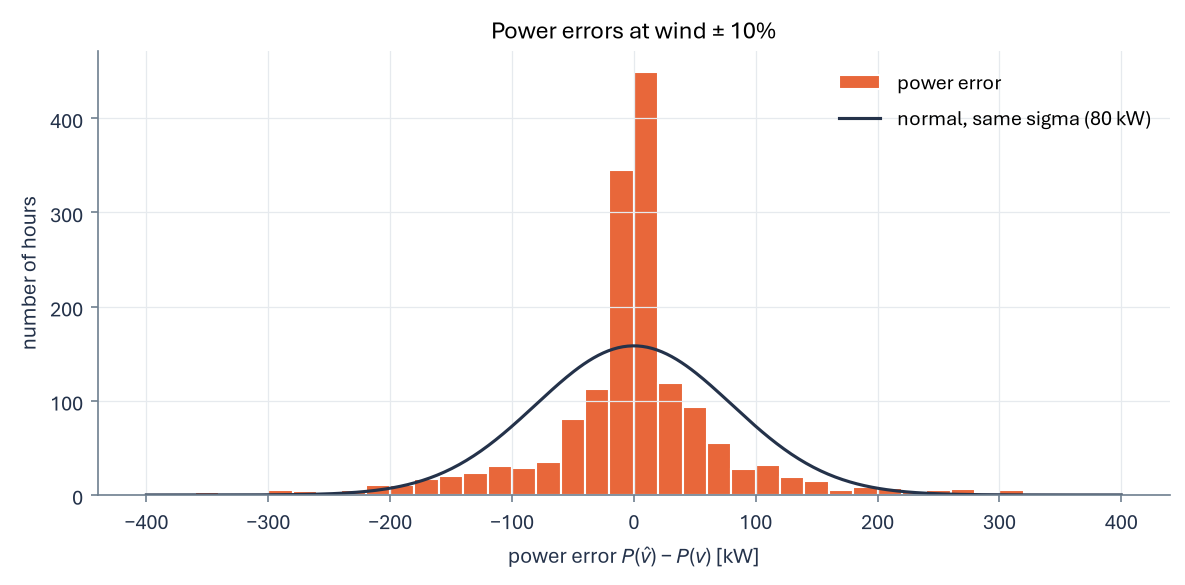

hours with |error| < 1 kW (flat parts of the curve): 18%; normal distribution would expect 1%
error of the curve with the exact wind: 23.8 kW (RMSE)


,all hours,0–3 m/s,3–5 m/s,5–7 m/s,7–9 m/s,9–11 m/s,≥ 11 m/s
wind ± 1%,90.3%,100.0%,98.6%,89.8%,76.1%,60.4%,93.2%
wind ± 5%,93.9%,100.0%,97.7%,90.1%,86.9%,90.1%,84.3%
wind ± 10%,92.0%,99.0%,93.2%,88.7%,90.6%,88.4%,73.6%


In [9]:
# 1. histogram of the power errors at 10 % noise, with a normal distribution with the same sigma
level = NOISE_LEVELS[-1]
column = NOISE_COLUMNS[-1]
dp = power_curve(bins, cal[column]) - p_exact
edges = np.arange(-400, 401, 20)
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(dp, bins=edges, color=ORANGE, edgecolor="white", label="power error")
x = np.linspace(-400, 400, 400)
# scale the density to number of hours per 20 kW bin
ax.plot(x, len(dp) * 20 * norm.pdf(x, 0, dp.std()), color=INK, lw=1.5, label=f"normal, same sigma ({dp.std():.0f} kW)")
ax.set(title=f"Power errors at wind ± {level:.0%}", xlabel=r"power error $P(\hat{v}) - P(v)$ [kW]", ylabel="number of hours")
ax.legend()
plt.tight_layout()
plt.show()
print(f"hours with |error| < 1 kW (flat parts of the curve): {(np.abs(dp) < 1).mean():.0%}; "
      f"normal distribution would expect {2 * norm.cdf(1 / dp.std()) - 1:.0%}")

# 2. share of calibration hours inside a Gaussian 90 % interval around P(v_noise), overall and per wind bin
sigma_curve = rmse(cal["p"] - p_exact)
coverage = {}
for level, column in zip(NOISE_LEVELS, NOISE_COLUMNS):
    v_noise = cal[column]
    sigma = np.sqrt((power_curve_slope(bins, v_noise) * level * v_noise) ** 2 + sigma_curve ** 2)
    inside = np.abs(cal["p"] - power_curve(bins, v_noise)) <= Z_90 * sigma
    wind_bin = pd.cut(v_noise, WIND_BINS, right=False, labels=WIND_BIN_LABELS)
    row = {"all hours": inside.mean()}
    row.update(inside.groupby(wind_bin, observed=True).mean().to_dict())
    coverage[f"wind ± {level:.0%}"] = row
coverage = pd.DataFrame(coverage).T
print(f"error of the curve with the exact wind: {sigma_curve:.1f} kW (RMSE)")
coverage.style.format("{:.1%}")

## 8. Same check in the bending part of the curve.

At 7 m/s the power error is almost normal, so $\pm\sigma_P$ describes it quite well. Now we do the same Monte Carlo check (same draws,
10 % noise) at 10.5 m/s, where the curve bends into rated power. There the wind band is $\pm 1.05$ m/s and reaches over the bend: on its
left the curve is still steep, on its right it is flat, so one slope cannot describe the whole band. For both wind speeds we compare the Gaussian prediction ($\sigma_P = |P'(v)|\,\sigma_v$ and
its 90 % band $\pm 1.645\,\sigma_P$) with the real 5 % and 95 % of the simulated power errors.

In the figure every curve has a strip on its right with the power errors of the draws, enlarged, and the normal distribution of
Gaussian error propagation as a dashed line.

,Gaussian sigma [kW],Gaussian 90 % band [kW],real 5 % [kW],real 95 % [kW],inside the Gaussian band
7.0 m/s,100,±165,-148,+192,89.3%
10.5 m/s,113,±185,-303,+52,84.3%


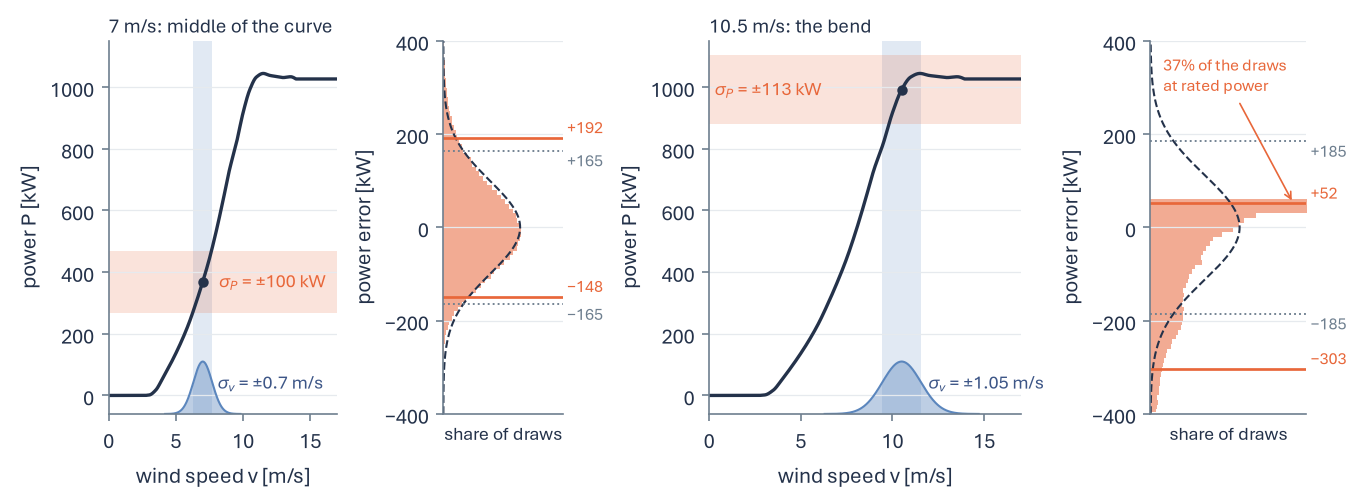

In [10]:
# the same check at two wind speeds with 10 % wind noise and the same draws: the middle of the curve and the bend
check_speeds = [7.0, 10.5]
level = NOISE_LEVELS[-1]
rows = {}
bend_errors = []
for v in check_speeds:
    dp = power_error_draws(v, level, eps_mc)
    sigma = abs(float(power_curve_slope(bins, v))) * level * v
    rows[f"{v} m/s"] = {
        "Gaussian sigma [kW]": sigma,
        "Gaussian 90 % band [kW]": Z_90 * sigma,
        "real 5 % [kW]": np.percentile(dp, 5),
        "real 95 % [kW]": np.percentile(dp, 95),
        "inside the Gaussian band": (np.abs(dp) <= Z_90 * sigma).mean(),
    }
    bend_errors.append(dp)
bend = pd.DataFrame(rows).T
display(bend.style.format({"Gaussian sigma [kW]": "{:.0f}", "Gaussian 90 % band [kW]": "±{:.0f}", "real 5 % [kW]": "{:+.0f}",
                           "real 95 % [kW]": "{:+.0f}", "inside the Gaussian band": "{:.1%}"}))


def draw_error_strip(ax, dp, sigma):
    """Distribution of the power errors of the draws, turned sideways, with the Gaussian prediction on top.

    Args:
        ax: Matplotlib axes.
        dp: Power errors of the draws in kW.
        sigma: Sigma of the power error from Gaussian error propagation in kW.
    """
    # share of the draws per kW in 10 kW bins (draws outside the plot also count)
    edges = np.arange(-400, 401, 10)
    counts, edges = np.histogram(dp, bins=edges)
    density = counts / len(dp) / 10
    mid = (edges[:-1] + edges[1:]) / 2
    ax.fill_betweenx(mid, 0, density, step="mid", color=ORANGE, alpha=0.55, lw=0)
    y = np.linspace(-400, 400, 400)
    ax.plot(norm.pdf(y, 0, sigma), y, "--", color=INK, lw=1)
    # Gaussian 90 % band (gray) and the real 5 % / 95 % of the draws (orange)
    low = np.percentile(dp, 5)
    high = np.percentile(dp, 95)
    for value in [-Z_90 * sigma, Z_90 * sigma]:
        ax.axhline(value, color=DARK_GRAY, lw=0.9, ls=":")
    for value in [low, high]:
        ax.axhline(value, color=ORANGE, lw=1.3)
    # the numbers right of the strip (x in axes units, y in kW): real values above their line, Gaussian values below
    labels = [(high, f"{high:+.0f}", ORANGE, "bottom"), (Z_90 * sigma, f"+{Z_90 * sigma:.0f}", DARK_GRAY, "top"),
              (low, f"{low:+.0f}", ORANGE, "bottom"), (-Z_90 * sigma, f"{-Z_90 * sigma:.0f}", DARK_GRAY, "top")]
    for value, text, color, va in labels:
        ax.annotate(text.replace("-", "−"), (1.0, value), xycoords=ax.get_yaxis_transform(), xytext=(2, 0),
                    textcoords="offset points", color=color, fontsize=8, ha="left", va=va)
    ax.set(xlim=(0, 0.0062), ylim=(-400, 400), xticks=[], yticks=[-400, -200, 0, 200, 400])
    ax.set_xlabel("share of draws", fontsize=9)
    ax.set_ylabel("power error [kW]")
    ax.grid(axis="x", visible=False)


# figure B: left the middle of the curve (7 m/s), right the bend (10.5 m/s); next to each the power errors, enlarged (slide 14)
fig, axes = plt.subplots(1, 4, figsize=(8.96, 3.25), width_ratios=[2.2, 1.15, 3.0, 1.5], layout="constrained")
headings = [f"{check_speeds[0]:g} m/s: middle of the curve", f"{check_speeds[1]:g} m/s: the bend"]
for i in range(len(check_speeds)):
    v = check_speeds[i]
    ax_curve = axes[2 * i]
    ax_strip = axes[2 * i + 1]
    p, sigma_v_i, sigma_p_i = draw_gauss_panel(ax_curve, v, level)
    ax_curve.set_title(headings[i], loc="left", fontsize=9.5, color=INK, pad=4)
    # sigma of the power where the plot is empty: right of the curve in the middle, left of the curve in the bend
    if p < 800:
        ax_curve.annotate(f"$\\sigma_P$ = ±{sigma_p_i:.0f} kW", (v + 1.2, p), color=ORANGE, fontsize=9, va="center")
    else:
        ax_curve.annotate(f"$\\sigma_P$ = ±{sigma_p_i:.0f} kW", (0.3, p), color=ORANGE, fontsize=9, va="center")
    ax_curve.annotate(f"$\\sigma_v$ = ±{sigma_v_i:.3g} m/s", (v + sigma_v_i + 0.4, 20), color=DEEP, fontsize=9)
    draw_error_strip(ax_strip, bend_errors[i], sigma_p_i)
# the bend: more than a third of the draws ends on the flat top of the curve (the bar is cut off), more power is not possible
dp = bend_errors[1]
share_top = (dp > dp.max() - 20).mean()
axes[3].annotate(f"{share_top:.0%} of the draws\nat rated power", (0.0057, 50), xytext=(0.0005, 370), color=ORANGE, fontsize=8,
                 va="top", arrowprops={"arrowstyle": "->", "color": ORANGE, "lw": 0.8})
fig.savefig(f"{FIGURE_DIR}/gauss_bend_comparison.png", transparent=False, facecolor="white")
plt.show()

Would one $\sigma$ per wind bin be enough? We check this for the questions after the talk. We use the bins of the predicted wind from
section 7 (the same as for Mondrian in notebook 04) and take as $\sigma_\text{bin}$ the standard deviation of the prediction errors
(measured power $- P(\hat v)$) of the calibration hours in each bin. The band is $P(\hat v) \pm 1.645\,\sigma_\text{bin}$.

In [11]:
# one sigma per bin of the predicted wind at 10 % noise: band P(v_noise) +/- 1.645 sigma of the errors in that bin
level = NOISE_LEVELS[-1]
column = NOISE_COLUMNS[-1]
v_noise = cal[column]
prediction_error = cal["p"] - power_curve(bins, v_noise)
wind_bin = pd.cut(v_noise, WIND_BINS, right=False, labels=WIND_BIN_LABELS)
rows = {}
for label in WIND_BIN_LABELS:
    err_bin = prediction_error[wind_bin == label]
    sigma_bin = err_bin.std()
    rows[label] = {
        "hours": len(err_bin),
        "band [kW]": Z_90 * sigma_bin,
        "real 5 % [kW]": np.percentile(err_bin, 5),
        "real 95 % [kW]": np.percentile(err_bin, 95),
        "inside, sigma per bin": (np.abs(err_bin) <= Z_90 * sigma_bin).mean(),
        "inside, Gaussian propagation": coverage.loc[f"wind ± {level:.0%}", label],
    }
sigma_per_bin = pd.DataFrame(rows).T
inside_bin = sigma_per_bin["inside, sigma per bin"]
inside_gauss = sigma_per_bin["inside, Gaussian propagation"]
print(f"hours inside, per bin: sigma per bin {inside_bin.min():.1%} to {inside_bin.max():.1%}, "
      f"Gaussian propagation {inside_gauss.min():.1%} to {inside_gauss.max():.1%}")
sigma_per_bin.style.format({"hours": "{:.0f}", "band [kW]": "±{:.0f}", "real 5 % [kW]": "{:+.0f}", "real 95 % [kW]": "{:+.0f}",
                            "inside, sigma per bin": "{:.1%}", "inside, Gaussian propagation": "{:.1%}"})

hours inside, per bin: sigma per bin 86.0% to 96.4%, Gaussian propagation 73.6% to 99.0%


,hours,band [kW],real 5 % [kW],real 95 % [kW],"inside, sigma per bin","inside, Gaussian propagation"
0–3 m/s,306,±10,-1,+6,96.4%,99.0%
3–5 m/s,546,±58,-44,+66,91.6%,93.2%
5–7 m/s,345,±141,-97,+170,90.7%,88.7%
7–9 m/s,223,±249,-215,+292,90.6%,90.6%
9–11 m/s,121,±250,-294,+217,86.0%,88.4%
≥ 11 m/s,53,±113,-174,+12,86.8%,73.6%


## 9. Save for notebook 04

We save the calibration hours with the measured wind and power and the three noisy wind speeds. Notebook 04 computes the conformal
intervals from them. Notebook 05 also uses the error table.

In [12]:
# calibration hours with the noisy wind
cal.to_csv("data/noisy_calibration.csv", index=False)

# error table and coverage of the Gaussian interval for the slides
noise_errors = errors.join(gauss[["Gaussian prediction"]])
noise_errors.index.name = "noise"
noise_errors.to_csv("data/noise_errors.csv")
coverage.index.name = "noise"
coverage.to_csv("data/gaussian_band_coverage.csv")
print(f"saved {len(cal)} hours with {len(NOISE_LEVELS)} noise levels")

saved 1594 hours with 3 noise levels


## Takeaways

- The shape of the power error is the main problem, not its size. A normal wind error goes in, but in the bend of the curve (10.5 m/s)
  the power error that comes out is almost one-sided: the turbine cannot produce more than rated power, so 90 % of the simulated errors
  are between -303 and +52 kW, while the Gaussian 90 % band says ±185 kW. Over the calibration hours the Gaussian band holds 99.0 % of
  the hours at 0-3 m/s but only 73.6 % at 11 m/s and more (10 % noise). So $\pm\sigma$ is no reliable interval, even when we know the
  size of the wind error exactly. With a real forecast we don't even know that input error. This is often the case in such data projects, which is why it is relevant to our peers. 
- The same relative wind noise gives a "tube" around the power curve. It is wide on the steep part and closes below cut-in and at rated
  power. Power RMSE: 8 kW at 1 % wind noise (not visible in the plot), 41 kW at 5 % and 80 kW at 10 %.
- The width of the tube is the slope times the wind error ($\sigma_P = |P'(v)|\,\sigma_v$). Gaussian error propagation predicts the power
  RMSE within 0.3 percentage points, also at 10 %. Example: at 7 m/s, 10 % wind noise (0.7 m/s) gives 100 kW or 27 % of the power.
- The factor 3 shows up in the RMSE: hour by hour on the steep part (4-10 m/s, 55 % of the hours) the relative power error is 3.3 times
  the relative wind error, close to the 3 from the cubic law. Over all hours (relative to the means) it is 2.8-2.9, because the flat parts
  add no error. The MAE ratio is lower (2.3-2.4) because the MAE gives more weight to the many small errors. The bias stays around 0.
  So the first guess "10 % wind error = 10 % power error" is far off.
- But the factor 3 only holds in the middle of the curve: the amplification $v\,P'(v)/P(v)$ is about 3 at 5-8 m/s, 6-10 just above
  cut-in, below 2 from 10 m/s on and 0 at rated power.
- The power errors are not normally distributed: 18 % of the hours have no error at all (a normal distribution would expect 1 %), and
  the tails are heavy. A "Gaussian 90 % interval" contains 90-94 % of the hours overall, but per bin of the predicted wind anywhere between
  60 % and 100 % (at 10 % noise: 74-99 %). So the size of the error is right, but it does not give a reliable interval.
- One $\sigma$ per wind bin fixes the size, but not the shape: 86.0-96.4 % of the hours per bin, and at 11 m/s and more the band is
  ±113 kW while the real errors are between -174 and +12 kW. Using the real 5th and 95th percentile per bin instead of $\pm 1.645\,\sigma$
  is exactly the Mondrian conformal prediction of notebook 04.

Next: notebook 04 uses conformal prediction, first with one interval for all hours and then with one interval per wind bin (Mondrian).